# Module 3 — Fraud Detection: run the whole module

**How to use:**
- **Run all** to run the full module in order (about 13 minutes; Task 2 takes most of it), or run a single cell to run one step.
- Each cell runs one task notebook in full and shows all its charts and main tables here; the task notebook itself shows every table.
- Every task notebook also runs on its own: open it from `notebooks/` and run all.

**Order matters:** later tasks read the files earlier tasks save in `outputs/taskN/`. Run the tasks in order, or rely on the files saved last time.

| Step | Notebook | Status |
| --- | --- | --- |
| 0. Data check | `helpers/m03_data.py` | Built |
| 1. Task 1 — Exploratory analysis | `notebooks/m03_task1_eda.ipynb` | Built |
| 2. Task 2 — Supervised fraud model | `notebooks/m03_task2_supervised.ipynb` | Built |
| 3. Task 3 — Unsupervised detection (Isolation Forest) | `notebooks/m03_task3_isolation_forest.ipynb` | Built |
| 4. Task 4 — Cost-based threshold | `notebooks/m03_task4_cost_threshold.ipynb` | Built |
| Final. Output workbook | `helpers/m03_final_output.py` → `outputs/FINAL_M3_module_output.xlsx` | Built |

Findings with charts: `reports/`. Status: `docs/progress.md`.


## Setup
Moves into the module folder so the paths below work, both locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.

In [1]:
import os
import sys
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]
os.chdir(PROJECT_ROOT / "module_03_fraud_detection")                  # the paths below start from the module folder
print("Working folder:", Path.cwd().name)

Working folder: module_03_fraud_detection


## 0. Data check
Is `nova_transactions.csv` complete and clean? Prints rows, missing values, duplicates, time range, customers, devices, fraud rate and the ₹ lost to fraud.

In [2]:
%run helpers/m03_data.py

rows: 30000
missing_values: 0
duplicate_transaction_ids: 0
time_range: ('2025-01-01', '2026-08-31')
customers: 2500
devices: 1500
fraud_rate: 0.0228
fraud_count: 684
fraud_value_crore: 2.01
transaction_types: {'Payment': 16515, 'Withdrawal': 7524, 'Transfer': 5961}
cities: 7


## 1. Task 1 — Exploratory analysis
Runs `notebooks/m03_task1_eda.ipynb` (under a minute).
- fraud rate overall, in ₹ and month by month;
- fraud by transaction type, amount, location, merchant category, customer behaviour, time, device and customer history;
- the evidence table: every column on the same yardsticks (significance after adjustment and single-column ROC-AUC);
- the Board view in ₹; saves `outputs/task1/FINAL_M3_T1_fraud_evidence.csv` for Task 2.

nbformat\__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


Project folder found
Outputs go to:  module_03_fraud_detection/outputs/task1
                      rows: 30000
            missing_values: 0
 duplicate_transaction_ids: 0
                time_range: ('2025-01-01', '2026-08-31')
                 customers: 2500
                   devices: 1500
                fraud_rate: 0.0228
               fraud_count: 684
         fraud_value_crore: 2.01
         transaction_types: {'Payment': 16515, 'Withdrawal': 7524, 'Transfer': 5961}
                    cities: 7
                    Amount: min 147.96, max 434,340.19, values ≤ 0: 0
Historical_Avg_Transaction: min 355.22, max 80,161.54, values ≤ 0: 0
        Account_Age_Months: min 3.00, max 179.00, values ≤ 0: 0
     Transaction_Frequency: min 1.00, max 27.00, values ≤ 0: 0

30,000 transactions over 608 days = 49 a day (the brief says 'thousands every day': this file is a sample)
Devices: 1,500; customers per device: median 20, devices used by more than one customer: 100%


Transactions                      30,000.00
Frauds                               684.00
Fraud rate                           0.0228
95% low                              0.0212
95% high                             0.0246
₹ in all transactions (crore)         32.28
₹ in fraud transactions (crore)        2.01
Fraud rate by money                  0.0622
Average fraud (₹)                 29,379.68
Average normal transaction (₹)    10,326.79
Median fraud (₹)                  26,437.99
Median normal transaction (₹)      6,411.09
Months differ? chi-square p = 0.65;  steady rise or fall? correlation +0.04, p = 0.87


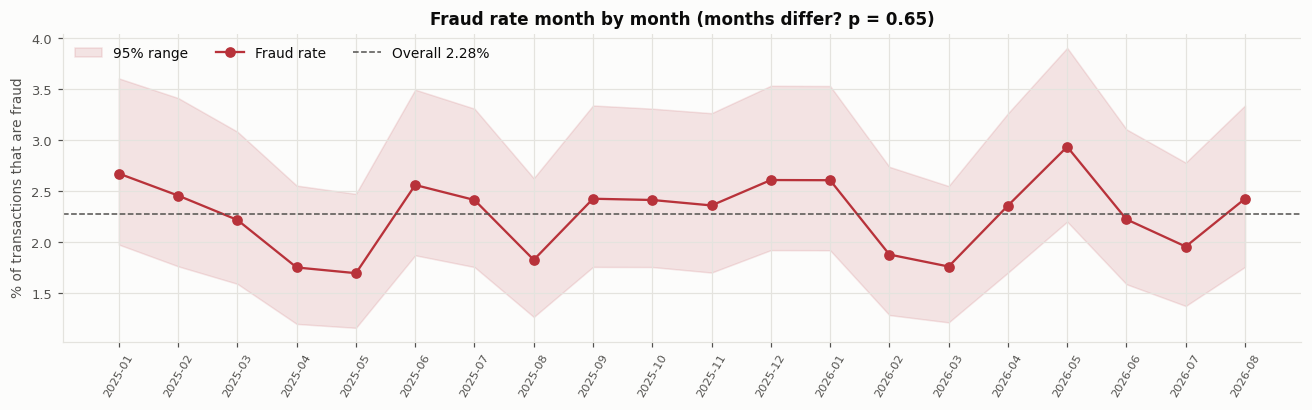

Tools ready.
Payment     2.09% vs the rest 2.51%: p = 0.0142
Transfer    2.97% vs the rest 2.11%: p = 0.0001
Withdrawal  2.15% vs the rest 2.32%: p = 0.3943
Types differ? chi-square p = 0.0003;  ROC-AUC 0.533
Tenths differ? chi-square p = 0.0e+00;  ROC-AUC 0.788 (higher → more fraud)


Notebook cell, line 8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "₹ in fraud (lakh)": g.apply(lambda s: s.Amount[s.Fraud_Flag == 1].sum()) / LAKH,


Largest transactions,From (₹),Fraud rate,Share of all frauds,Share of fraud ₹
1%,"₹67,733",13.7%,6%,21%
5%,"₹33,738",15.2%,33%,64%
10%,"₹23,331",12.7%,56%,85%
20%,"₹15,118",7.5%,66%,92%


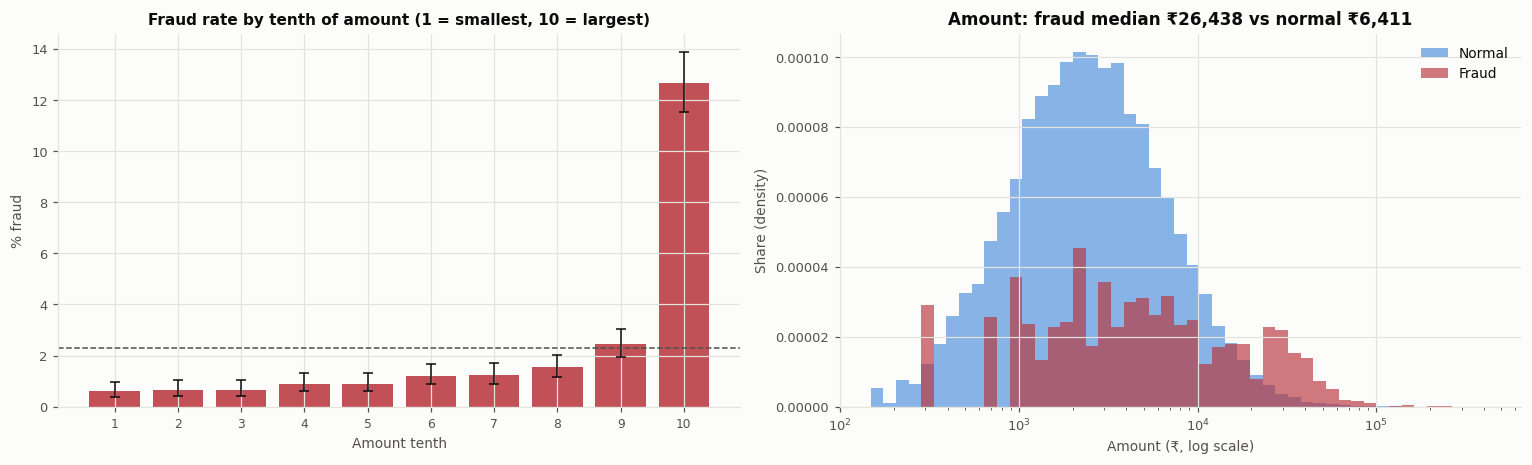

Notebook cell, line 8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "₹ in fraud (lakh)": g.apply(lambda s: s.Amount[s.Fraud_Flag == 1].sum()) / LAKH,
Notebook cell, line 8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "₹ in fraud (lakh)": g.apply(lambda s: s.Amount[s.Fraud_Flag == 1].sum()) / LAKH,


Cities differ? chi-square p = 0.96;  ROC-AUC 0.513
Categories differ? chi-square p = 0.43;  ROC-AUC 0.526


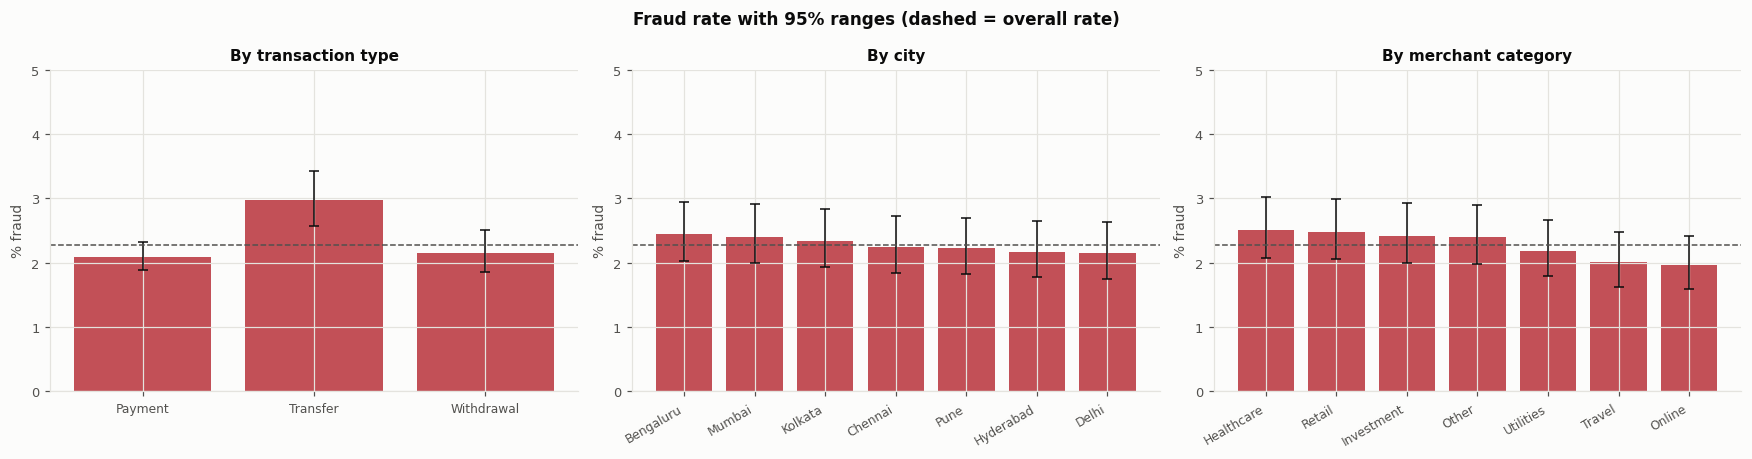

Historical_Avg_Transaction   groups 10 | p = 4.8e-09 | ROC-AUC 0.583 (lower → more fraud) | rate 1.1% → 3.3%
Amount_Ratio                 groups 10 | p = 2.6e-255 | ROC-AUC 0.787 (higher → more fraud) | rate 0.5% → 10.3%


Account_Age_Months           groups 10 | p = 1.6e-01 | ROC-AUC 0.519 (higher → more fraud) | rate 1.6% → 2.8%
Transaction_Frequency        groups  8 | p = 2.9e-01 | ROC-AUC 0.517 (lower → more fraud) | rate 2.0% → 2.7%

Median Amount_Ratio: fraud 5.00× the usual amount, normal 1.17×
Correlation of Amount with Amount_Ratio: 0.71 (how much the two strong columns overlap)
Correlation of Amount with Historical_Avg_Transaction: 0.00
                                 weight    p
const                          -10.7508  0.0
ln(Amount)                       1.1605  0.0
ln(Historical_Avg_Transaction)  -0.4485  0.0


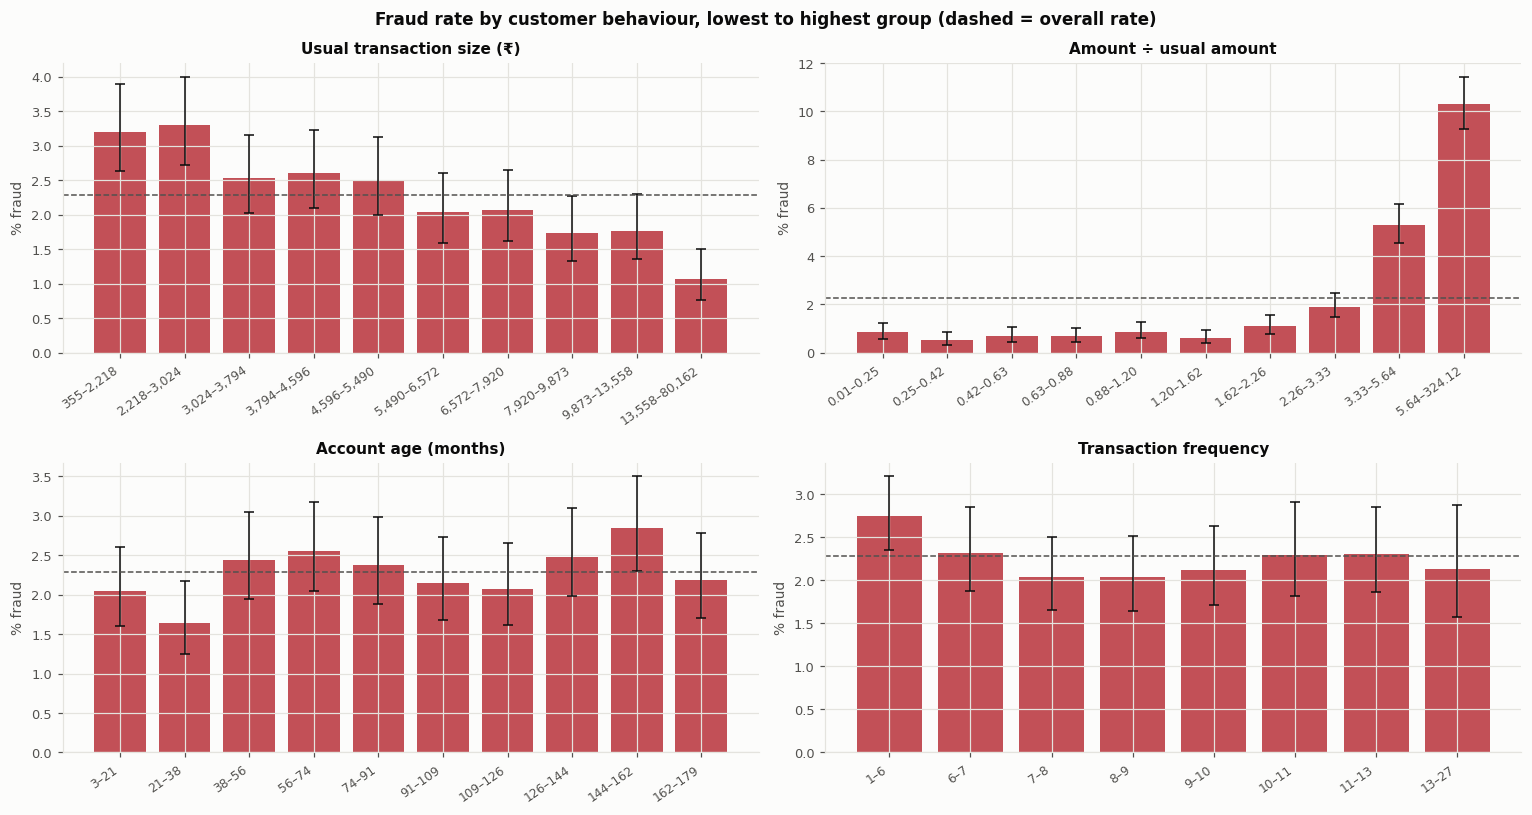

Notebook cell, line 8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "₹ in fraud (lakh)": g.apply(lambda s: s.Amount[s.Fraud_Flag == 1].sum()) / LAKH,


Hours differ? p = 0.33, ROC-AUC 0.526;  days differ? p = 0.82, ROC-AUC 0.518


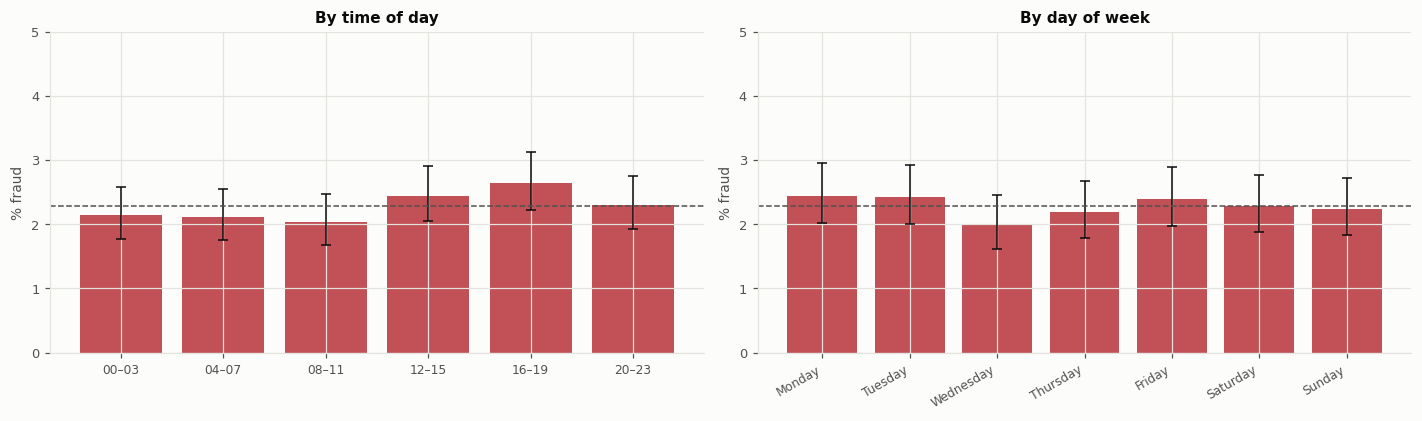

Transactions with an earlier one from the same customer: 27,500 of 30,000
Device change: share changed 99.95% | rates {'Changed': 0.0227, 'No change': 0.0714} | p = 0.74 | ROC-AUC 0.501
Location change: share changed 85.68% | rates {'Changed': 0.0225, 'No change': 0.0244} | p = 0.49 | ROC-AUC 0.505
Frauds cluster on devices: 1,500 Device_IDs, frauds per Device_ID: {0: 961, 1: 412, 2: 110, 3: 16, 4: 1} | p = 0.046


Device had an earlier fraud: rates {'Earlier fraud': 0.0247, 'No earlier fraud': 0.0223} | p = 0.31 | ROC-AUC 0.508
Frauds cluster on customers: 2,500 Customer_IDs, frauds per Customer_ID: {0: 1898, 1: 527, 2: 68, 3: 7} | p = 0.611


Customer had an earlier fraud: rates {'Earlier fraud': 0.0218, 'No earlier fraud': 0.0229} | p = 0.71 | ROC-AUC 0.503
16 tests; Bonferroni line p < 0.0031
0.60 line: weakest Strong ROC-AUC 0.787, strongest other 0.583 → any line between them gives the same verdicts
Verdicts that change at a plain 0.05: Frauds cluster on devices (Not informative → Weak)


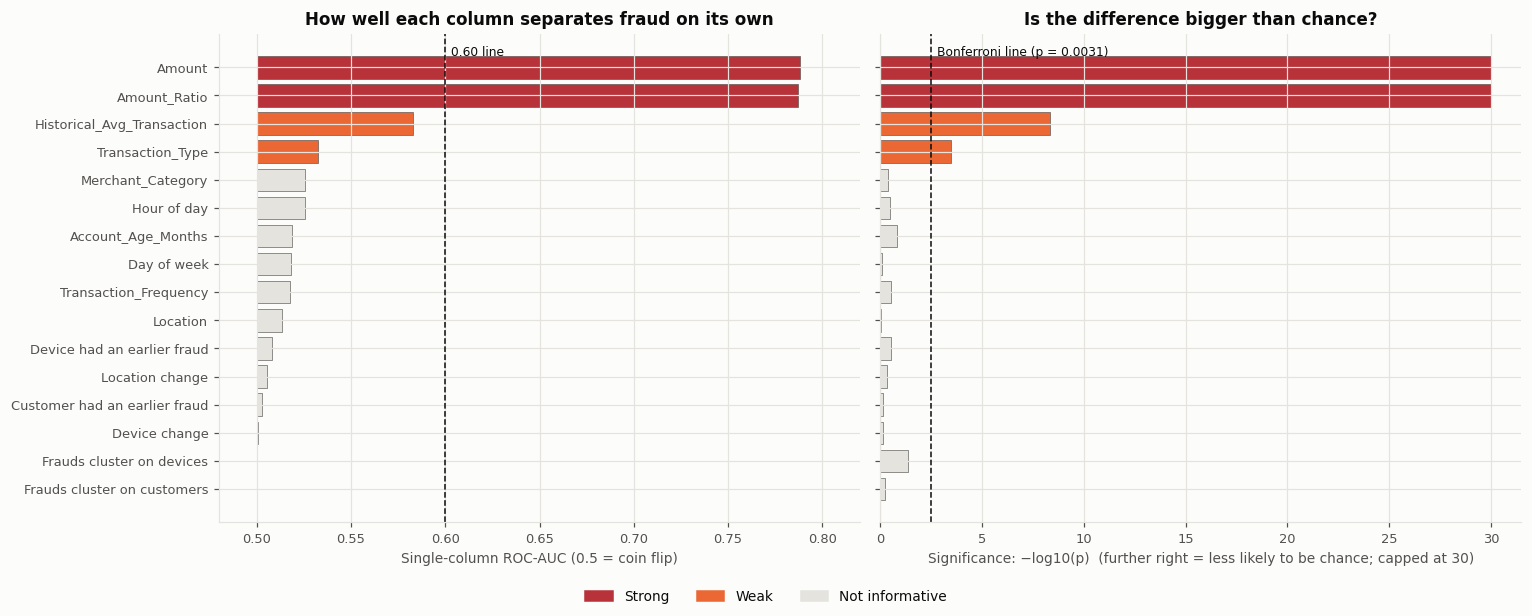

Notebook cell, line 8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "₹ in fraud (lakh)": g.apply(lambda s: s.Amount[s.Fraud_Flag == 1].sum()) / LAKH,


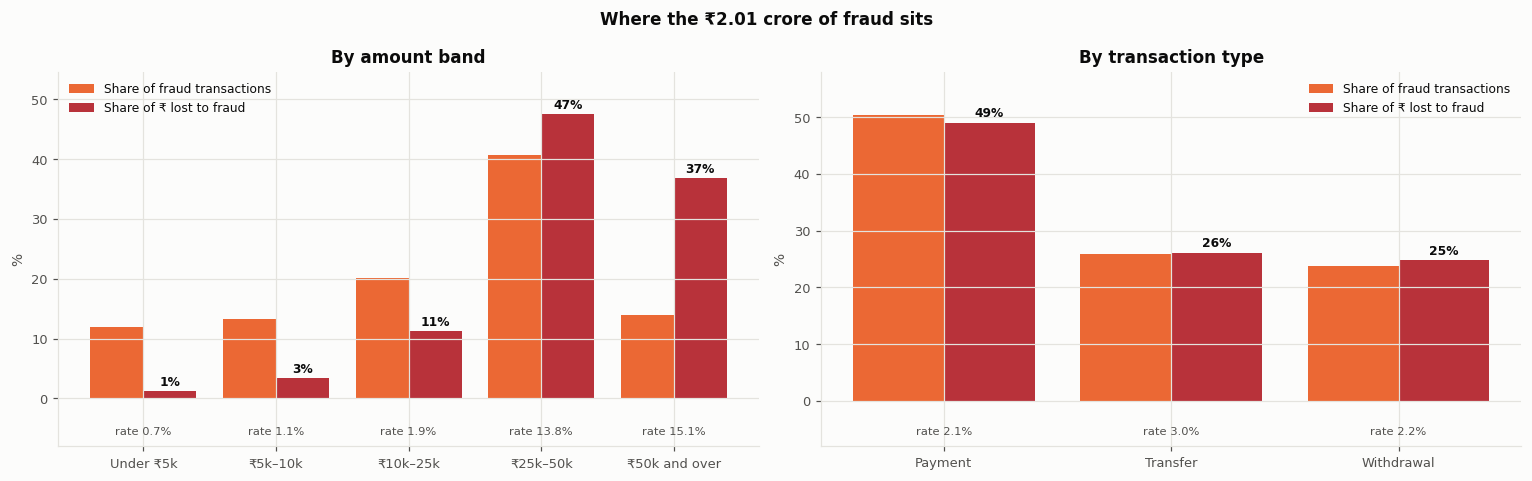

Saved to module_03_fraud_detection/outputs/task1
['01_fraud_rate_by_month.png', '02_fraud_by_amount.png', '03_fraud_by_type_city_merchant.png', '04_fraud_by_customer_behaviour.png', '05_fraud_by_time.png', '06_evidence_table.png', '07_board_view.png', 'FINAL_M3_T1_fraud_evidence.csv', 'key_numbers.json']


In [3]:
%run notebooks/m03_task1_eda.ipynb

## 2. Task 2 — Supervised fraud model
Runs `notebooks/m03_task2_supervised.ipynb` (about 11 minutes: 11 model set-ups × 25 rounds, some tuned inside each round).
- split by time and the leakage checks;
- amount alone (benchmark) vs logistic, lasso, decision tree, random forest and LightGBM, on two input sets;
- overfitting check and the agreed selection rule; the final test on 6,000 later transactions;
- the finance case: frauds and fraud ₹ caught at every investigation budget;
- calibration (reported), SHAP and example transactions;
- saves `outputs/task2/FINAL_M3_T2_fraud_scores.csv` (each transaction's score) for Tasks 3 and 4.

Project folder found
Outputs go to:  module_03_fraud_detection/outputs/task2


,Transactions,Frauds,Fraud rate,From,To,₹ in fraud (crore)
Training,24000,540,0.0225,2025-01-01,2026-05-01,1.610147
Test,6000,144,0.024,2026-05-01,2026-08-31,0.399423


PASS  Fraud_Flag in no input
PASS  All training before all test
PASS  First transaction of each customer shows no change
PASS  Usual amount unrelated to current amount (correlation +0.003; frauds -0.055)
Strong + weak   5 inputs: ln_Amount, ln_Amount_Ratio, ln_Historical_Avg_Transaction, Transaction_Type_Transfer, Transaction_Type_Withdrawal
All columns    28 inputs: ln_Amount, ln_Amount_Ratio, ln_Historical_Avg_Transaction, Transaction_Type_Transfer, Transaction_Type_Withdrawal, Merchant_Category_Investment, Merchant_Category_Online, Merchant_Category_Other, Merchant_Category_Retail, Merchant_Category_Travel, Merchant_Category_Utilities, Location_Chennai, Location_Delhi, Location_Hyderabad, Location_Kolkata, Location_Mumbai, Location_Pune, Account_Age_Months, Transaction_Frequency, Hour, Weekday_Tuesday, Weekday_Wednesday, Weekday_Thursday, Weekday_Friday, Weekday_Saturday, Weekday_Sunday, Device_Change, Location_Change
11 set-ups: Amount alone [Amount only], Logistic [Strong + weak],

Amount alone   [Amount only  ]     1s | PR-AUC 0.1158 | ROC-AUC 0.788 | gap +0.000


Logistic       [Strong + weak]     1s | PR-AUC 0.1266 | ROC-AUC 0.801 | gap +0.001


Logistic       [All columns  ]     2s | PR-AUC 0.1261 | ROC-AUC 0.796 | gap +0.009


... (4 outputs left out)

Random forest  [Strong + weak]    63s | PR-AUC 0.1243 | ROC-AUC 0.779 | gap +0.140


Random forest  [All columns  ]    52s | PR-AUC 0.1336 | ROC-AUC 0.790 | gap +0.130


LightGBM       [Strong + weak]    51s | PR-AUC 0.1318 | ROC-AUC 0.794 | gap +0.056


LightGBM       [All columns  ]    64s | PR-AUC 0.1354 | ROC-AUC 0.793 | gap +0.075


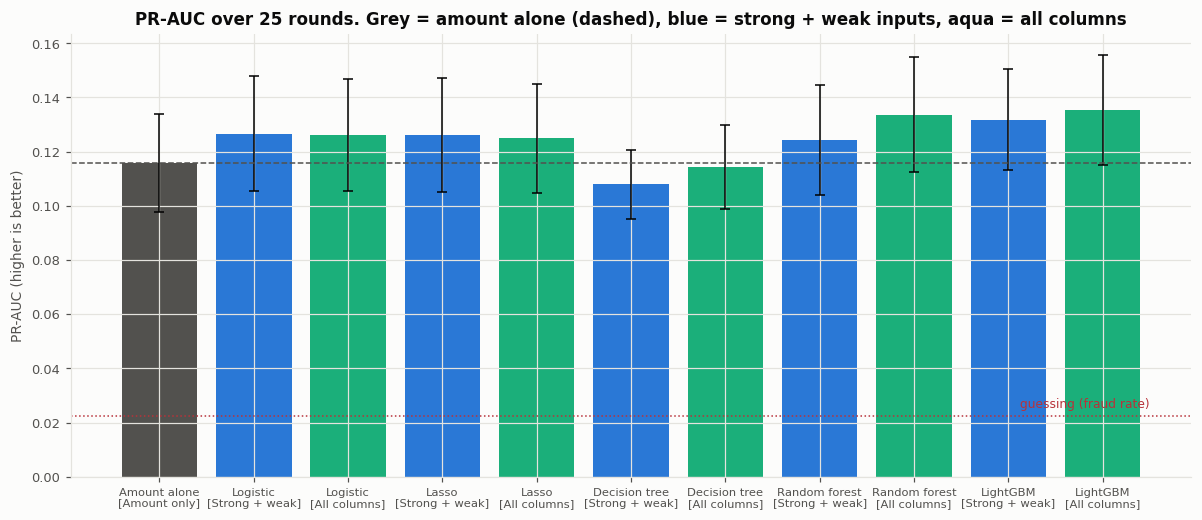

Ruled out: Random forest [Strong + weak], Random forest [All columns]


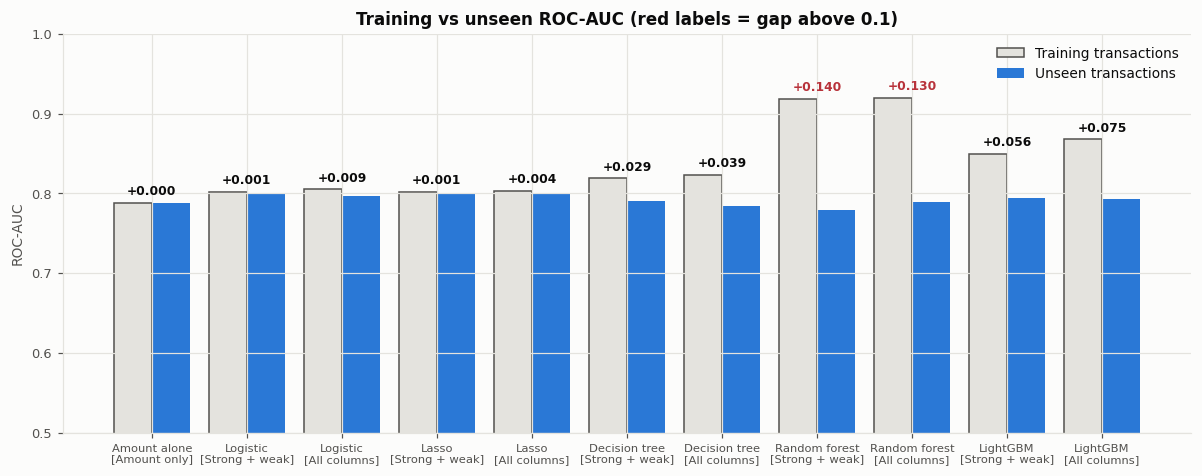

Best PR-AUC: LightGBM [All columns] = 0.1354
CHOSEN (simplest within chance of the best): LightGBM [Strong + weak]
Chosen vs amount alone: PR-AUC +0.0160 (95% range +0.0098 to +0.0223), better in 22 of 25 rounds


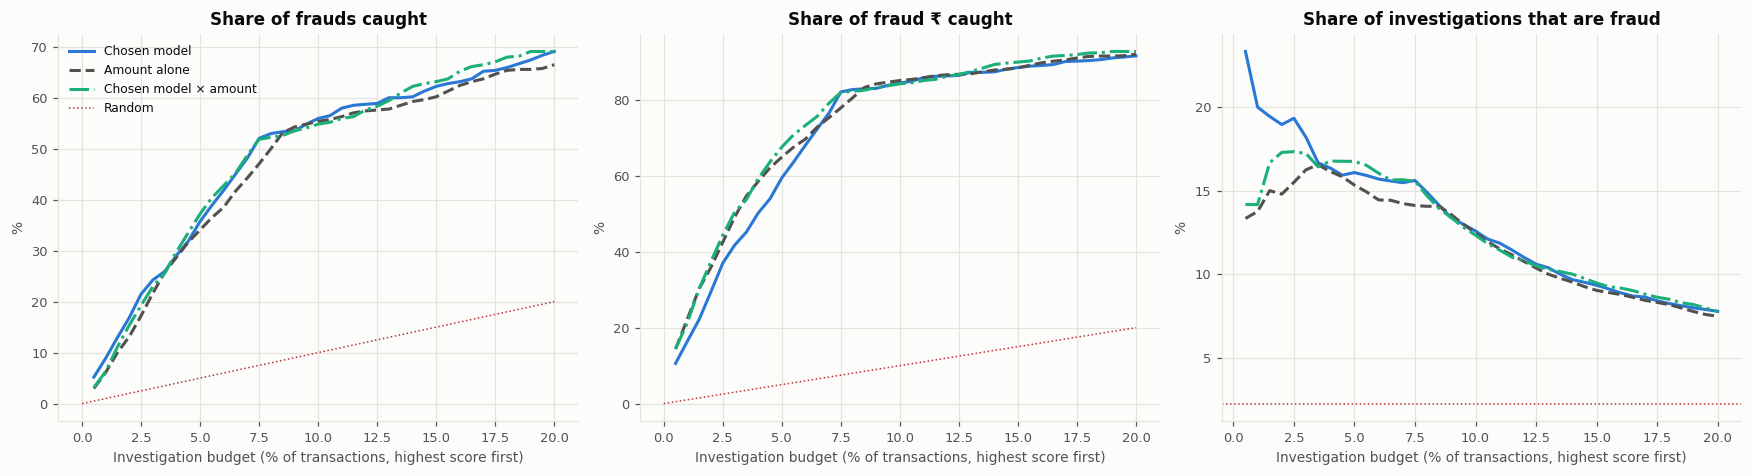

Fraud ₹ per 1,000 transactions (training period): ₹670,895


Budget,Measure,Chosen,Amount alone,Difference,95% low,95% high
1%,Frauds caught,9.3%,6.1%,+3.1%,+2.0%,+4.3%
1%,Fraud ₹ caught,16.4%,22.0%,-5.6%,-8.5%,-2.8%
5%,Frauds caught,35.9%,34.2%,+1.7%,+0.4%,+3.1%
5%,Fraud ₹ caught,58.8%,64.7%,-6.0%,-8.9%,-3.1%
10%,Frauds caught,55.7%,55.3%,+0.4%,-0.4%,+1.2%
10%,Fraud ₹ caught,84.2%,84.9%,-0.7%,-1.2%,-0.1%


Accuracy at a 50% cut-off: chosen 97.60% (flags 0 transactions); calling everything honest: 97.60%


,Chosen model,Always the fraud rate
Training (out-of-fold),0.02049,0.02199
Test,0.02182,0.02343


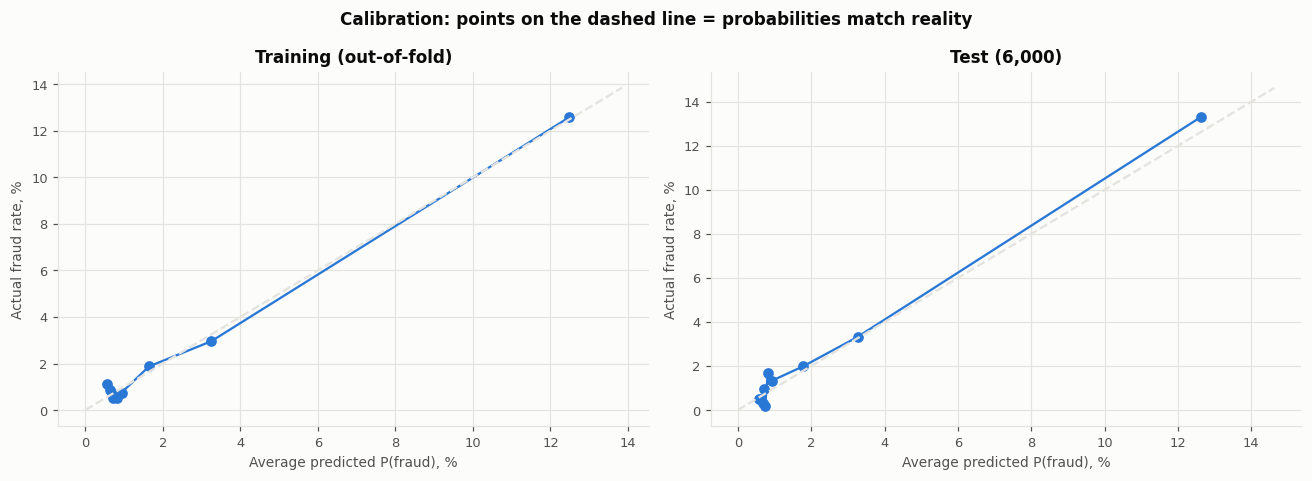

Share of the model's reliance on the two strong Task 1 columns (amount, amount ratio): 88%
ln_Amount_Ratio                  0.534
ln_Amount                        0.348
Transaction_Type_Transfer        0.068
ln_Historical_Avg_Transaction    0.045
Transaction_Type_Withdrawal      0.005


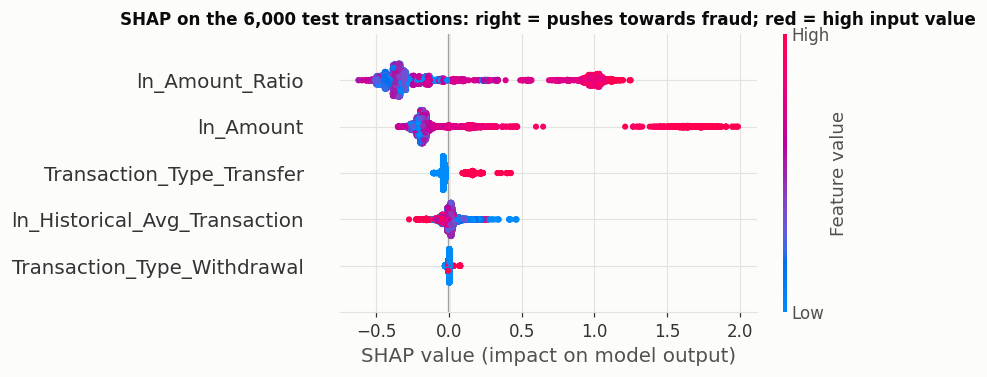

Saved to module_03_fraud_detection/outputs/task2
['01_cv_comparison.png', '02_overfitting_check.png', '03_catch_curves.png', '04_calibration.png', '05_shap_summary.png', 'FINAL_M3_T2_fraud_scores.csv', 'chosen_model.joblib', 'chosen_model.json', 'cv_summary.csv', 'key_numbers.json']


In [4]:
%run notebooks/m03_task2_supervised.ipynb

## 3. Task 3 — Unsupervised detection (Isolation Forest)
Runs `notebooks/m03_task3_isolation_forest.ipynb` (about 2 minutes). Reads `outputs/task2/FINAL_M3_T2_fraud_scores.csv`, so Task 2 must have run first.
- Isolation Forest fitted on training transactions without the fraud label; the input tests;
- the comparison on 6,000 test transactions: amount alone vs supervised vs Isolation Forest, in frauds and in ₹;
- overlap (which frauds each finds) and combining the two;
- saves `outputs/task3/unusual_transactions.csv` (the transactions identified as unusual, each with its reasons) and `FINAL_M3_T3_anomaly_scores.csv` for Task 4.

Reads from:    module_03_fraud_detection/outputs/task2
Outputs go to: module_03_fraud_detection/outputs/task3


Training 24,000 (540 frauds), test 6,000 (144 frauds)
Share to flag as unusual = training-period fraud rate = 540 ÷ 24,000 = 2.25%


Guessing scores PR-AUC = fraud rate = 0.022
Share of training transactions per value (smallest – largest):
  Transaction_Type   20.0% – 55.0%
  Merchant_Category  13.8% – 14.6%
  Location           14.1% – 14.6%
  Weekday            14.2% – 14.4%
Fraud rate by how rare the type × merchant × city combination is (rarest fifth first): ['2.7%', '2.2%', '2.3%', '1.7%', '2.2%']
Fraud rate, city new for the customer vs not: {'seen before': '2.3%', 'new': '2.2%'}


Cut-off anomaly score (from training): 0.5975
Flagged as unusual: training 540 (2.25%), test 140 (2.33%)


Two seeds share 93% of the unusual list on average (lowest 91%)


,Transactions,Fraud_rate,Median_amount,Median_ratio,Median_usual,Median_account_age,Median_frequency
Not flagged,"29,320",2.01%,"₹6,374",1.17,"₹5,519",91,9
Flagged unusual,680,13.82%,"₹60,518",17.64,"₹4,128",93,9


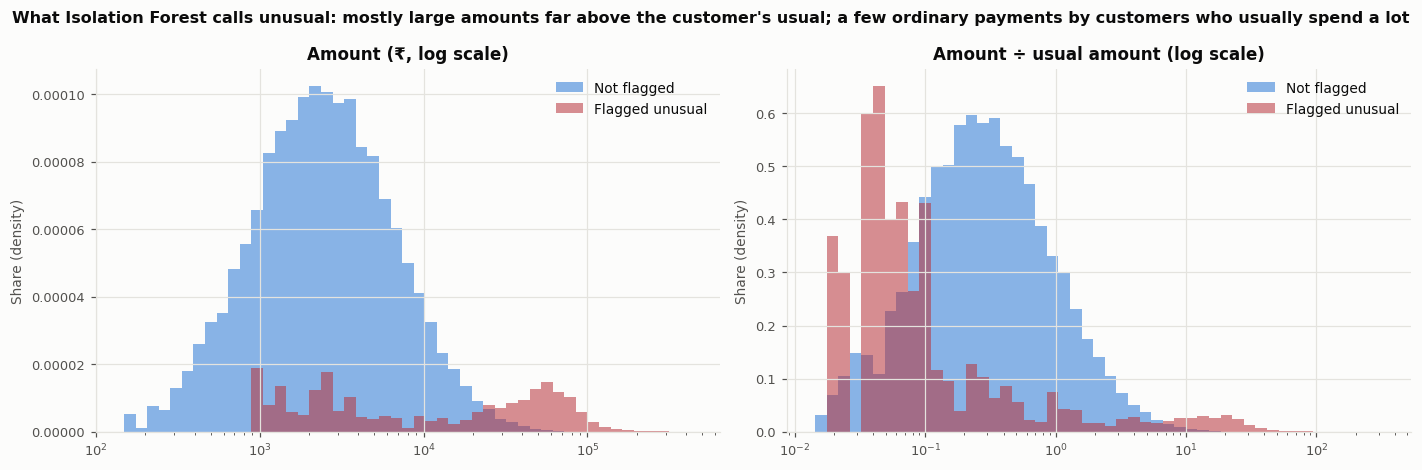

Test transactions: 6,000; frauds: 144; guessing PR-AUC = 0.024
Fraud ₹ per 1,000 test transactions: ₹665,705


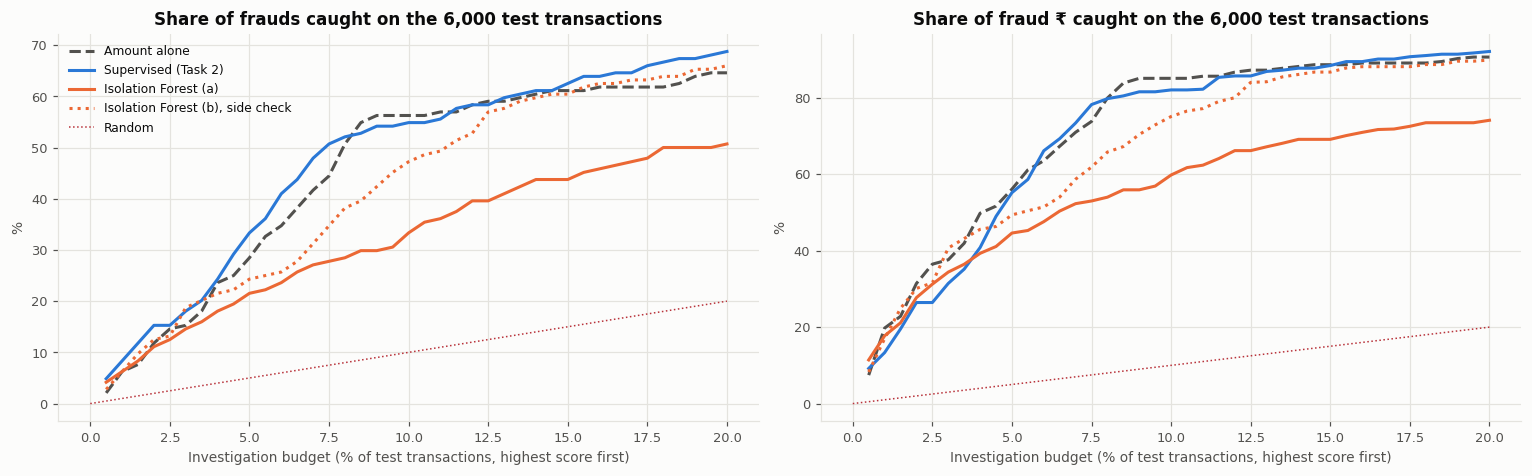

Ordinary-looking = amount below ₹15,162 (training 80th percentile); 51 of 144 test frauds


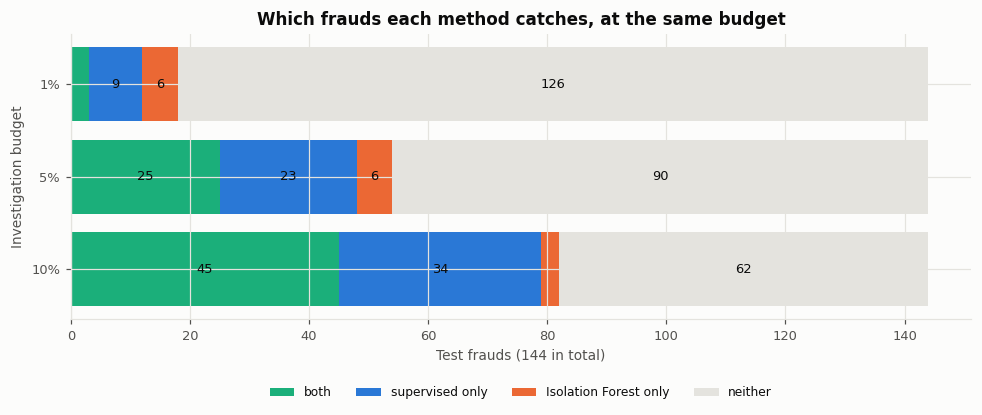

Blended rank PR-AUC: 0.107 (supervised 0.124, Isolation Forest 0.074)


,Flagged,Fraud,Also_supervised
Set,,,
test,140,12.1%,36%
train,540,14.3%,43%


Main reason (the input pushing hardest towards 'unusual'): {'Amount_Ratio': 325, 'Amount': 265, 'Historical_Avg_Transaction': 85, 'Transaction_Frequency': 5}


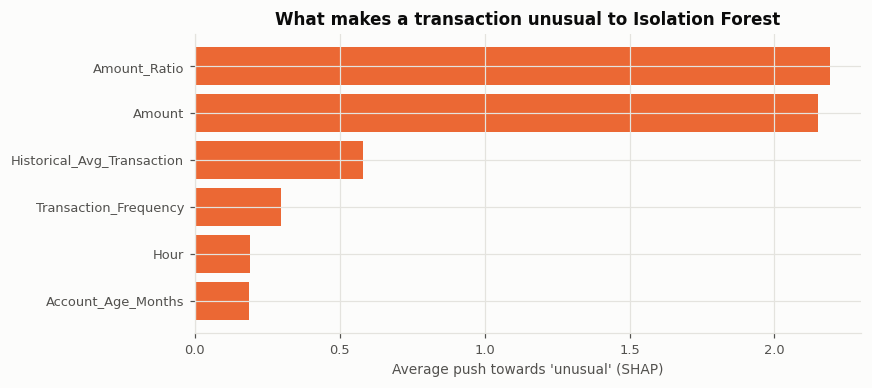

Saved to module_03_fraud_detection/outputs/task3
['01_what_is_unusual.png', '02_catch_curves.png', '03_overlap.png', '04_why_unusual.png', 'FINAL_M3_T3_anomaly_scores.csv', 'comparison.csv', 'isolation_forest.joblib', 'isolation_forest.json', 'key_numbers.json', 'unusual_transactions.csv']


In [5]:
%run notebooks/m03_task3_isolation_forest.ipynb

## 4. Task 4 — Cost-based threshold
Runs `notebooks/m03_task4_cost_threshold.ipynb` (under a minute). Reads Task 2's and Task 3's scores.
- the threshold from the brief's costs (investigate when the chance of fraud is above 4.76%) and the check that the model's chances are honest around it;
- cross-check by trying every cut-off; the real cost on the 6,000 test transactions;
- the finance view (each missed fraud at its real amount); how the line moves if the costs change;
- saves `outputs/task4/FINAL_M3_T4_transaction_decisions.csv` (Investigate / Let through for every transaction) and `threshold_summary.csv`.

Missed fraud ₹10,000; wasted check ₹500; the line = 500 ÷ 10,500 = 4.76%


Training: 24,000 transactions, 540 frauds (2.25%), fraud ₹161.0 lakh
Test: 6,000 transactions, 144 frauds (2.40%), fraud ₹39.9 lakh
All four checks pass: True → use the line
Sweep's cheapest cut-off on training: P(fraud) ≥ 7.10%, investigating 7.5%, ₹139,333 per 1,000
The line (4.76%) on training: investigating 8.3%, ₹141,354 per 1,000
Investigate nothing: ₹225,000;  everything: ₹488,750


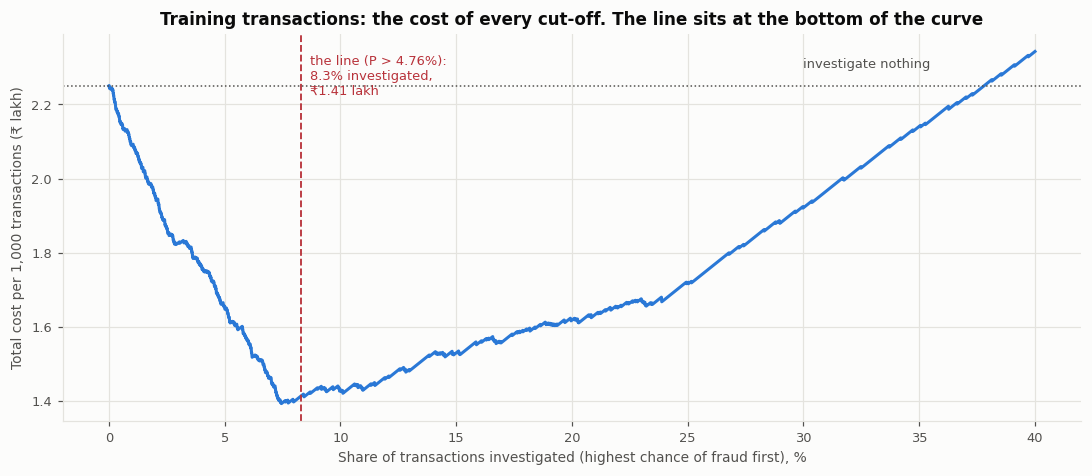

Calibration checks passed: True → the answer uses the line


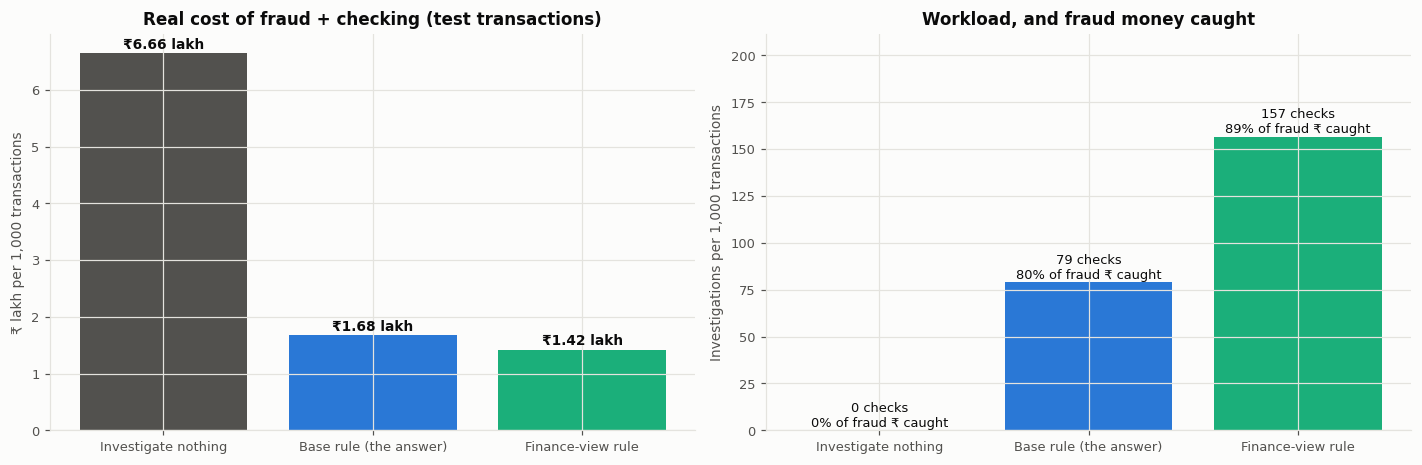

Saved to module_03_fraud_detection/outputs/task4
['01_cost_curve_training.png', '02_board_view.png', 'FINAL_M3_T4_transaction_decisions.csv', 'key_numbers.json', 'module9_inputs.csv', 'threshold_summary.csv']
Cost of fraud risk per ₹ moved: 1.55% with the rule (no screening 6.13%); fraud × 3: 4.03% (no screening 18.38%)


,0
Category,Digital banking: cost of fraud risk
What NovaFin would put money into,The ML fraud rule (P(fraud) > 4.76%) on Digital banking's payments
Return per ₹ deployed (% a year),-1.55
Return range (% a year),−1.55% with the rule vs −6.13% with no screening (per ₹ of money moved)
Bad-year result per ₹ (% a year),-4.03
How the bad year is defined,Fraud three times as common (missed fraud × 3); no screening: −18.38%
Capacity (₹ crore),Scales with the money moved
Evidence strength,Strong: tested on unseen transactions; costs from the brief
How fast the money can come back,Not a capital use: a cost per ₹ moved
Data gap or assumption,"No fee revenue in the data: Digital banking's return per ₹ of capital comes from Module 1 (Digital Banking 13.2%, Pa..."


In [6]:
%run notebooks/m03_task4_cost_threshold.ipynb

## Final output workbook
Builds **`outputs/FINAL_M3_module_output.xlsx`**: the one file to open for this module's results (project decision P-21).
- Tabs: Read me · Key numbers · Board actions · each task's final file · Hand-off to Module 9 · Decisions · Evidence index.
- Every hand-off figure is computed from the task tabs' rows, and each row says which tab, column(s) and rows it comes from.
- Run after all the tasks above.

In [7]:
%run helpers/m03_final_output.py

Saved: FINAL_M3_module_output.xlsx
                                                              Figure                                                                                                                                                                                                                                       Value                   Unit
                                  Money moved per 1,000 transactions                                                                                                                                                                                                                                      108.68                 ₹ lakh
                                    Cost of fraud risk, no screening                                                                                                                                                                                                                                        6.13     